Bluesky Followers and Post Engagement: A Data Report

Name: Amari Brown
Date: October 20, 2026

Research Question: Do Bluesky accounts with more followers receive more likes on their posts?

Hypothesis: Bluesky accounts with more followers tend to receive more likes on their posts.

Theoretical Application

This hypothesis explores the relationship between audience size and social media engagement. Accounts with more followers may have a larger audience to see and like their posts. However, other factors, such as the topic of a post and how active an account’s followers are, may also affect engagement.

Statistical Application

I will collect profile information and post engagement data from Bluesky using its public API. I will combine the datasets using pandas and compare follower counts with the number of likes on posts. I will use summary statistics and visualizations to look for patterns. If enough observations are available, I will also examine the correlation between followers and likes.

Variables

* DID: Unique identifier for each Bluesky account.
* Handle: The account’s username.
* Followers Count: Number of followers an account has.
* Post URI: Unique identifier for a post.
* Like Count: Number of likes received by a post.
* Repost Count: Number of times a post has been reposted.
* Reply Count: Number of replies received by a post.

The independent variable is the number of followers, and the dependent variable is the number of likes received by a post.

Data Sources and API Endpoints

This report uses publicly available information from the Bluesky API. The API provides information about user profiles and posts that can be collected using Python’s requests library.

Endpoint 1: app.bsky.actor.getProfile

This endpoint retrieves profile information for a Bluesky account. I will use the account’s DID, handle, follower count, following count, and total post count. These variables help describe the size and activity of each account.

Endpoint 2: app.bsky.feed.getAuthorFeed

This endpoint retrieves feed items associated with an account. I will use the post URI, author information, likes, reposts, and replies. These variables help measure engagement with posts.

I will combine the datasets using the account’s DID and handle. This will connect the profile information to the engagement information for each account’s posts.

Reliability and Limitations

The API provides structured information in JSON format, making it easier to collect and organize data consistently. However, the information can change as accounts gain followers and posts receive additional engagement.

The author-feed endpoint returns a limited number of feed items rather than every post an account has ever made. The feed may also contain reposts, which can affect the analysis. Some posts or accounts may be unavailable, and certain fields may be missing.

The selected accounts may not represent all Bluesky users. Other factors, such as posting frequency, post topics, and audience activity, may influence engagement. Therefore, the results can show a possible relationship between followers and likes, but they cannot prove that having more followers causes more likes.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://public.api.bsky.app/xrpc/"

handles = [
    "bsky.app",
    "jay.bsky.team"
]

print("Libraries imported successfully.")

Libraries imported successfully.


Collecting Profile Data

The first API request retrieves profile information from Bluesky. I will collect the DID, handle, follower count, following count, and total post count for each account. I will check whether the requests are successful before processing the JSON responses.

In [2]:
profiles = []

for handle in handles:
    response = requests.get(
        BASE_URL + "app.bsky.actor.getProfile",
        params={"actor": handle},
        timeout=20
    )

    response.raise_for_status()
    profile = response.json()

    profiles.append({
        "did": profile.get("did"),
        "handle": profile.get("handle"),
        "followersCount": profile.get("followersCount"),
        "followingCount": profile.get("followsCount"),
        "postCount": profile.get("postsCount")
    })

profiles_df = pd.DataFrame(profiles)

display(profiles_df)



,did,handle,followersCount,followingCount,postCount
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886
1,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,594464,3994,4185


Collecting Post Engagement Data

The second API request retrieves recent feed items from each account. I will collect the post URI, author, like count, repost count, and reply count. These variables will help me examine how much engagement each post receives.

The API may return reposts along with other feed items, so I will identify reposts where possible and exclude them from the main analysis.



In [3]:
posts = []

for _, profile in profiles_df.iterrows():
    response = requests.get(
        BASE_URL + "app.bsky.feed.getAuthorFeed",
        params={
            "actor": profile["did"],
            "limit": 100
        },
        timeout=20
    )

    response.raise_for_status()
    feed_data = response.json()

    for item in feed_data.get("feed", []):
        post = item.get("post", {})
        record = post.get("record", {})
        author = post.get("author", {})

        posts.append({
            "did": author.get("did"),
            "handle": author.get("handle"),
            "post_uri": post.get("uri"),
            "text": record.get("text", ""),
            "likeCount": post.get("likeCount", 0),
            "repostCount": post.get("repostCount", 0),
            "replyCount": post.get("replyCount", 0),
            "is_repost": item.get("reason") is not None
        })

posts_df = pd.DataFrame(posts)

display(posts_df.head())
print("Number of feed items collected:", len(posts_df))

,did,handle,post_uri,text,likeCount,repostCount,replyCount,is_repost
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,yes. here's what the film we were discussing i...,14,3,1,False
1,did:plc:z4llsx425l4htoylyyx6iam3,antlervel.vet,at://did:plc:z4llsx425l4htoylyyx6iam3/app.bsky...,Hello! I got a bunch of lovely feedback from f...,515,43,130,True
2,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,we held an interview with the director of a do...,48,3,2,False
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,STREAMING LIVE NOW: stream.place/niedermeyer....,395,82,23,False
4,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,"if you remember none pizza with left beef, it'...",1817,212,90,False


Number of feed items collected: 198


Combining and Cleaning the Data

I will use the pandas merge() method to combine the profile and post DataFrames. The DID and handle will be used as shared keys. This allows each post’s engagement information to be connected to the profile’s follower count.

After merging, I will remove feed items identified as reposts and check for missing values in the variables needed for the analysis. This will help prepare the final dataset for comparison and visualization.

Exploring the Final Dataset

Before analyzing the results, I will examine the final DataFrame and calculate summary statistics. These statistics will show the number of observations and the distribution of followers, likes, reposts, and replies.

Checking the data will also help identify missing information that could affect the conclusions.

In [8]:

final_df = pd.merge(
    profiles_df,
    posts_df,
    on=["did", "handle"],
    how="inner"
)

original_posts_df = final_df[
    final_df["is_repost"] == False
].copy()

numeric_columns = [
    "followersCount",
    "likeCount",
    "repostCount",
    "replyCount"
]

for column in numeric_columns:
    original_posts_df[column] = pd.to_numeric(
        original_posts_df[column],
        errors="coerce"
    )

analysis_df = original_posts_df.dropna(
    subset=["followersCount", "likeCount"]
).copy()

print("Data prepared successfully!")
print("Rows available:", len(analysis_df))

display(analysis_df.head())


Data prepared successfully!
Rows available: 153


,did,handle,followersCount,followingCount,postCount,post_uri,text,likeCount,repostCount,replyCount,is_repost
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,yes. here's what the film we were discussing i...,14,3,1,False
1,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,we held an interview with the director of a do...,48,3,2,False
2,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,STREAMING LIVE NOW: stream.place/niedermeyer....,395,82,23,False
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,"if you remember none pizza with left beef, it'...",1817,212,90,False
4,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35322356,22,886,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,bluesky: home of character actor enthusiasts,182,5,3,False


In [10]:

print("Dataset shape:")
print(analysis_df.shape)

print("Missing values:")
print(analysis_df.isnull().sum())

print("Summary statistics:")
display(analysis_df.describe())

print("Average likes by account:")
account_summary = analysis_df.groupby(
    "handle"
)["likeCount"].mean()

display(account_summary)



Dataset shape:
(153, 11)
Missing values:
did               0
handle            0
followersCount    0
followingCount    0
postCount         0
post_uri          0
text              0
likeCount         0
repostCount       0
replyCount        0
is_repost         0
dtype: int64
Summary statistics:


,followersCount,followingCount,postCount,likeCount,repostCount,replyCount
count,1.530000e+02,153.000000,153.000000,153.000000,153.000000,153.000000
mean,1.829888e+07,1969.058824,2503.156863,545.150327,80.320261,26.457516
std,1.741762e+07,1992.139118,1654.598930,1417.928120,337.333090,75.530317
min,5.944640e+05,22.000000,886.000000,3.000000,0.000000,0.000000
25%,5.944640e+05,22.000000,886.000000,19.000000,0.000000,1.000000
50%,3.532236e+07,22.000000,886.000000,78.000000,4.000000,4.000000
75%,3.532236e+07,3994.000000,4185.000000,401.000000,23.000000,16.000000
max,3.532236e+07,3994.000000,4185.000000,9627.000000,3353.000000,659.000000


Average likes by account:


handle
bsky.app         930.525641
jay.bsky.team    144.360000
Name: likeCount, dtype: float64

Visualizing the Results

I will create a scatter plot comparing follower counts with the number of likes received by posts. This visualization will help identify whether accounts with more followers tend to have posts with higher like counts.

The plot is descriptive rather than proof of causation. Since each account can contribute multiple posts, the observations are not fully independent.

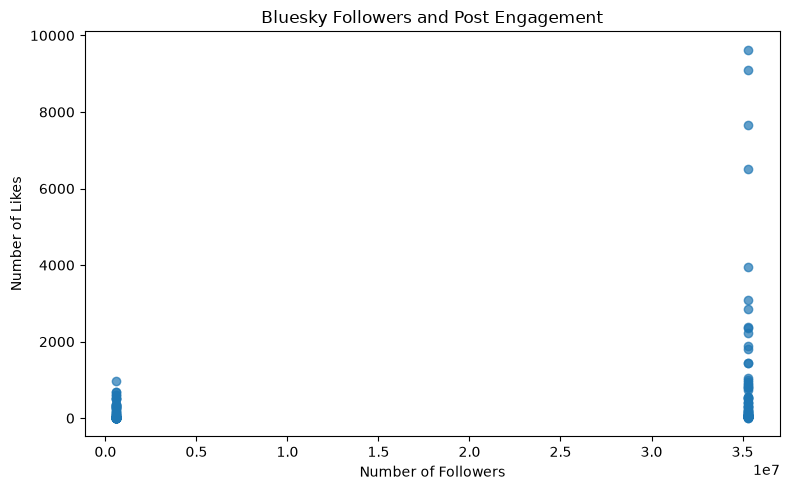

In [11]:
if not analysis_df.empty:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        analysis_df["followersCount"],
        analysis_df["likeCount"],
        alpha=0.7
    )

    plt.xlabel("Number of Followers")
    plt.ylabel("Number of Likes")
    plt.title("Bluesky Followers and Post Engagement")

    plt.tight_layout()
    plt.show()
else:
    print("No data is available to create the scatter plot.")

In [14]:
if len(analysis_df) > 1:
    print(analysis_df[["followersCount", "likeCount"]].corr())
else:
    print("Not enough data to calculate correlation.")


                followersCount  likeCount
followersCount         1.00000    0.27808
likeCount              0.27808    1.00000


|The results show whether accounts with more followers tend to receive more likes. The data may be limited because only a few accounts and posts were studied. Future research should include more accounts and posts.